# Heart Disease Prediction

Predicting whether a patient has heart disease from 13 clinical measurements.

**Workflow:** load data, explore, baseline model, compare models with cross-validation, tune, evaluate, interpret.

| Feature | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (1-4) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | Resting ECG result (0-2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise |
| slope | Slope of the peak exercise ST segment (1-3) |
| ca | Number of major vessels (0-3) coloured by fluoroscopy |
| thal | Thalassemia test result (3 = normal, 6 = fixed defect, 7 = reversible defect) |
| target | 1 = heart disease, 0 = healthy (original 0-4 scale converted to binary) |

## 1. Imports

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)
from google.colab import files
uploaded = files.upload()

RANDOM_STATE = 2
os.makedirs('images', exist_ok=True)
sns.set_theme(style='whitegrid')

Saving processed.cleveland.data to processed.cleveland.data


## 2. Load and inspect the data

In [4]:
cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
        'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# The UCI file has no header row and uses '?' for missing values
heart_data = pd.read_csv('processed.cleveland.data', header=None, names=cols, na_values='?')

# UCI target: 0 = no disease, 1-4 = disease. Convert to a 0/1 label.
heart_data['target'] = (heart_data['target'] > 0).astype(int)

print('Rows with missing values:', heart_data.isnull().any(axis=1).sum())
heart_data = heart_data.dropna().reset_index(drop=True)
print('Rows, columns:', heart_data.shape)
heart_data.head()

Rows with missing values: 6
Rows, columns: (297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [5]:
heart_data.info()
print('\nMissing values per column (after cleaning):')
print(heart_data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  target    297 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 32.6 KB

Missing values per column (after cleaning):
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal  

In [6]:
heart_data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,3.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,4.730640,0.461279
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,1.938629,0.499340
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


## 3. Exploratory data analysis

target
0    160
1    137
Name: count, dtype: int64


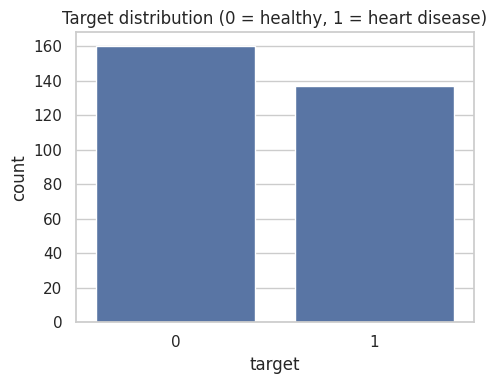

In [7]:
counts = heart_data['target'].value_counts().sort_index()
print(counts)

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='target', data=heart_data, ax=ax)
ax.set_title('Target distribution (0 = healthy, 1 = heart disease)')
plt.tight_layout()
plt.savefig('images/target_distribution.png', dpi=150)
plt.show()

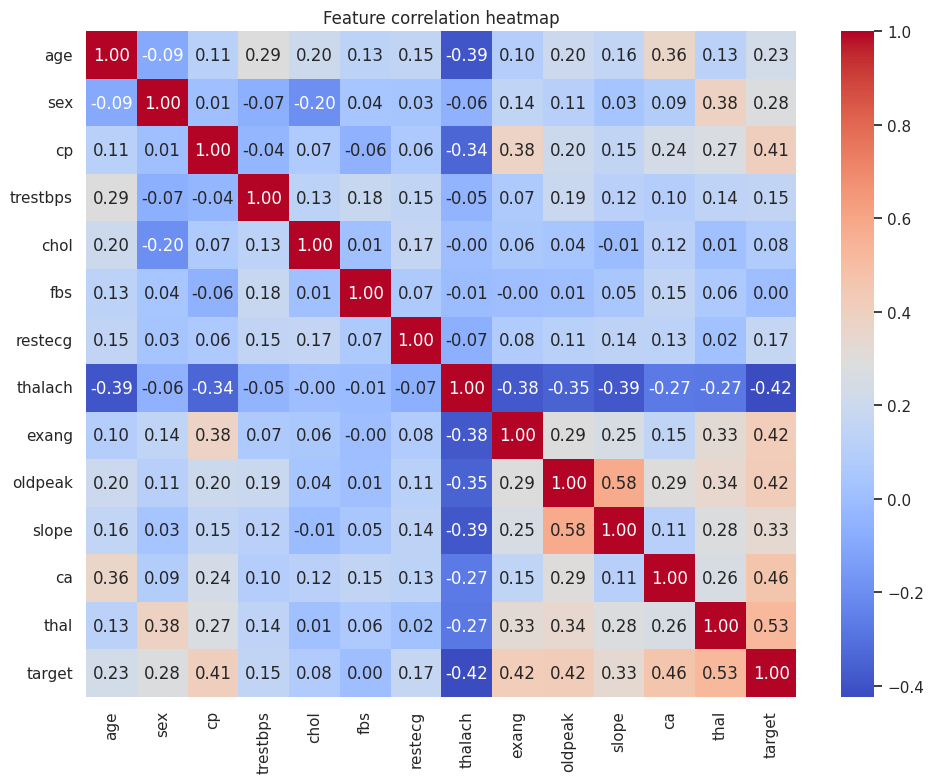

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(heart_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Feature correlation heatmap')
plt.tight_layout()
plt.savefig('images/correlation_heatmap.png', dpi=150)
plt.show()

## 4. Train / test split

80/20 split, stratified so both sets keep the same class balance. The test set stays untouched until the final evaluation.

In [9]:
X = heart_data.drop(columns='target')
Y = heart_data['target']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=RANDOM_STATE)
print(X.shape, X_train.shape, X_test.shape)

(297, 13) (237, 13) (60, 13)


## 5. Baseline: Logistic Regression on raw features

The starting point: no scaling, default settings. Scikit-learn may warn that the solver did not converge, because the features sit on very different scales (cholesterol in the hundreds, ST depression near 0 to 6). Scaling is the fix, applied in the next section.

In [10]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    baseline = LogisticRegression()
    baseline.fit(X_train, Y_train)

print('Baseline accuracy on training data:', round(accuracy_score(Y_train, baseline.predict(X_train)), 4))
print('Baseline accuracy on test data    :', round(accuracy_score(Y_test, baseline.predict(X_test)), 4))

Baseline accuracy on training data: 0.865
Baseline accuracy on test data    : 0.8333


## 6. Compare models

Each model is wrapped in a pipeline so scaling is learned **only from the training folds** during cross-validation (no data leakage). Models are ranked by 5-fold cross-validated accuracy on the training set, which is a steadier measure than a single split on 303 rows.

In [11]:
def make_pipe(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

models = {
    'Logistic Regression': make_pipe(LogisticRegression(max_iter=1000)),
    'KNN':                 make_pipe(KNeighborsClassifier()),
    'SVM (RBF)':           make_pipe(SVC()),
    'Random Forest':       make_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
}

def get_scores(fitted, X_, y_):
    if hasattr(fitted, 'predict_proba'):
        return fitted.predict_proba(X_)[:, 1]
    return fitted.decision_function(X_)

def evaluate(name, pipe, cv_acc=None):
    pipe.fit(X_train, Y_train)
    pred = pipe.predict(X_test)
    return {
        'Model': name,
        'CV Accuracy': cv_acc,
        'Test Accuracy': accuracy_score(Y_test, pred),
        'Precision': precision_score(Y_test, pred),
        'Recall': recall_score(Y_test, pred),
        'F1': f1_score(Y_test, pred),
        'ROC-AUC': roc_auc_score(Y_test, get_scores(pipe, X_test, Y_test)),
    }

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    cv_acc = cross_val_score(pipe, X_train, Y_train, cv=skf, scoring='accuracy').mean()
    rows.append(evaluate(name, pipe, cv_acc))

results = pd.DataFrame(rows).sort_values('CV Accuracy', ascending=False).reset_index(drop=True)
display(results.round(3))

,Model,CV Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.831,0.833,0.800,0.857,0.828,0.893
1,Random Forest,0.818,0.800,0.767,0.821,0.793,0.891
2,KNN,0.810,0.867,0.833,0.893,0.862,0.867
3,SVM (RBF),0.806,0.850,0.828,0.857,0.842,0.896


## 7. Hyperparameter tuning (GridSearchCV)

In [12]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10, 100]},
    'Random Forest': {
        'model__n_estimators': [100, 300],
        'model__max_depth': [3, 5, None],
        'model__min_samples_leaf': [1, 3, 5],
    },
}

tuned = {}
for name, grid in param_grids.items():
    gs = GridSearchCV(models[name], grid, cv=skf, scoring='accuracy', n_jobs=-1)
    gs.fit(X_train, Y_train)
    tuned[name] = gs
    print(f"{name}: best CV accuracy = {gs.best_score_:.3f}")
    print('   best params:', gs.best_params_)

Logistic Regression: best CV accuracy = 0.843
   best params: {'model__C': 0.1}
Random Forest: best CV accuracy = 0.835
   best params: {'model__max_depth': 5, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}


## 8. Final model and evaluation on the held-out test set

The model with the best cross-validated score after tuning is evaluated once on the test set.

In [13]:
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
print('Selected model:', best_name)

final = evaluate(best_name + ' (tuned)', best_model, tuned[best_name].best_score_)
final_df = pd.DataFrame([final])
display(final_df.round(3))

pred = best_model.predict(X_test)
print(classification_report(Y_test, pred, target_names=['Healthy (0)', 'Heart disease (1)']))

Selected model: Logistic Regression


,Model,CV Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (tuned),0.843,0.833,0.8,0.857,0.828,0.903


                   precision    recall  f1-score   support

      Healthy (0)       0.87      0.81      0.84        32
Heart disease (1)       0.80      0.86      0.83        28

         accuracy                           0.83        60
        macro avg       0.83      0.83      0.83        60
     weighted avg       0.84      0.83      0.83        60



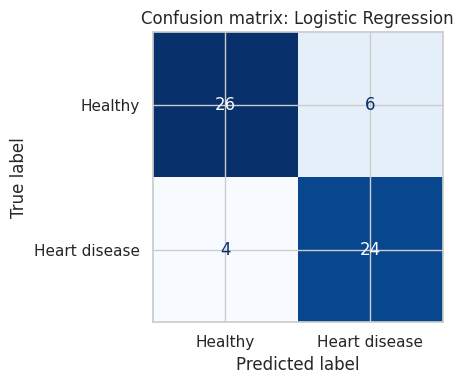

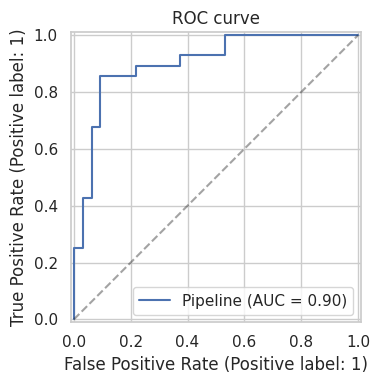

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(Y_test, pred),
                       display_labels=['Healthy', 'Heart disease']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix: {best_name}')
plt.tight_layout()
plt.savefig('images/confusion_matrix.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_estimator(best_model, X_test, Y_test, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax.set_title('ROC curve')
plt.tight_layout()
plt.savefig('images/roc_curve.png', dpi=150)
plt.show()

**Why recall matters here:** in medical screening a false negative (a sick patient labelled healthy) is more costly than a false positive, so recall is checked alongside accuracy.

## 9. Which features matter most?

Permutation importance on the test set: how much the ROC-AUC drops when one feature's values are shuffled. It works for any model type.

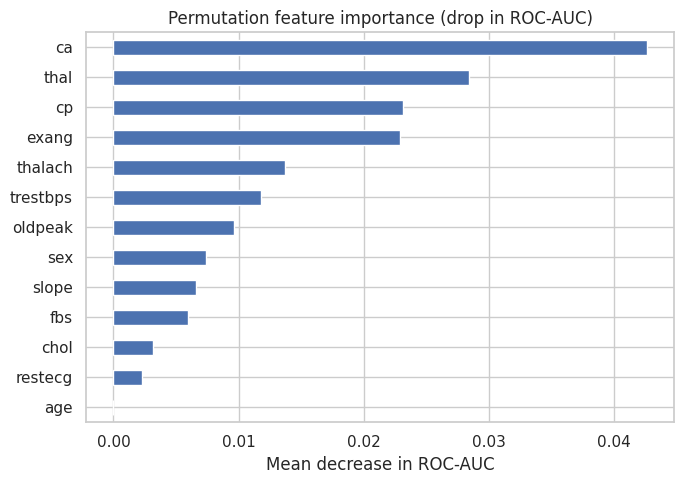

Top 3 features: ['ca', 'thal', 'cp']


In [15]:
perm = permutation_importance(best_model, X_test, Y_test, scoring='roc_auc',
                              n_repeats=30, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
importance.plot(kind='barh', ax=ax)
ax.set_title('Permutation feature importance (drop in ROC-AUC)')
ax.set_xlabel('Mean decrease in ROC-AUC')
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=150)
plt.show()

print('Top 3 features:', list(importance.sort_values(ascending=False).head(3).index))

## 10. Predictive system

In [16]:
# Predict for one real patient from the test set
sample = X_test.iloc[[0]]
print(sample.T)

prediction = best_model.predict(sample)
print('\nPredicted:', prediction[0], '| Actual:', Y_test.iloc[0])
if prediction[0] == 0:
    print('The person does not have heart disease')
else:
    print('The person has heart disease')

             25
age        50.0
sex         0.0
cp          3.0
trestbps  120.0
chol      219.0
fbs         0.0
restecg     0.0
thalach   158.0
exang       0.0
oldpeak     1.6
slope       2.0
ca          0.0
thal        3.0

Predicted: 0 | Actual: 0
The person does not have heart disease


## 11. Limitations and next steps

- Only 303 records, so scores vary with the split; cross-validation helps but a larger dataset is needed to trust the numbers.
- The data comes from one study population and may not generalise to other patients.
- Next: try gradient boosting, calibrate the probabilities, and serve the model in a small Streamlit app.

*Educational project, not a medical diagnostic tool.*

In [17]:
# Markdown table of the comparison results, ready to paste into the README
cols = ['Model', 'CV Accuracy', 'Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
all_rows = pd.concat([results, final_df], ignore_index=True)[cols]
print('| ' + ' | '.join(cols) + ' |')
print('|' + '---|' * len(cols))
for _, r in all_rows.iterrows():
    print(f"| {r['Model']} | " + ' | '.join(f"{r[c]:.3f}" for c in cols[1:]) + ' |')

| Model | CV Accuracy | Test Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.831 | 0.833 | 0.800 | 0.857 | 0.828 | 0.893 |
| Random Forest | 0.818 | 0.800 | 0.767 | 0.821 | 0.793 | 0.891 |
| KNN | 0.810 | 0.867 | 0.833 | 0.893 | 0.862 | 0.867 |
| SVM (RBF) | 0.806 | 0.850 | 0.828 | 0.857 | 0.842 | 0.896 |
| Logistic Regression (tuned) | 0.843 | 0.833 | 0.800 | 0.857 | 0.828 | 0.903 |
